In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", None)

# Carregamento
df = pd.read_csv("/transacoes_historico_2025.csv")
df_jan = pd.read_csv("/transacoes_jan2026.csv")

# Conversão temporal
for base in [df, df_jan]:
    base["datahora_transacao"] = pd.to_datetime(
        base["datahora_transacao"],
        errors="coerce"
    )

# Auditoria
def auditar_base(base, nome):
    print(f"\n{'='*55}")
    print(f"BASE: {nome}")
    print(f"{'='*55}")
    print(f"Dimensão: {base.shape}")
    print(f"Duplicatas: {base.duplicated().sum()}")
    print(f"Valores ausentes: {base.isna().sum().sum()}")
    print("\nTipos de dados:")
    print(base.dtypes)
    print("\nCardinalidade:")
    print(base.nunique().sort_values(ascending=False))

auditar_base(df, "Histórico 2025")
auditar_base(df_jan, "Janeiro 2026")

# Verificar compatibilidade dos esquemas
features_2025 = set(df.columns) - {"flag_fraude"}
features_jan = set(df_jan.columns)

print("\nVariáveis ausentes em janeiro:")
print(features_2025 - features_jan)

print("\nVariáveis extras em janeiro:")
print(features_jan - features_2025)



BASE: Histórico 2025
Dimensão: (523525, 15)
Duplicatas: 0
Valores ausentes: 0

Tipos de dados:
datahora_transacao      datetime64[ns]
nome_estabelecimento            object
tipo_estabelecimento            object
valor_transacao                float64
nome_cliente                    object
cidade                          object
flag_fraude                       bool
device_type                     object
is_new_device                     bool
temperatura_celsius            float64
codigo_postal                   object
score_interno                    int64
turno                           object
valor_categoria                 object
cidade_regiao                   object
dtype: object

Cardinalidade:
datahora_transacao      523525
codigo_postal           521905
valor_transacao          29246
nome_cliente             26214
score_interno             1001
temperatura_celsius        533
nome_estabelecimento        10
cidade                       7
tipo_estabelecimento         6
turno     

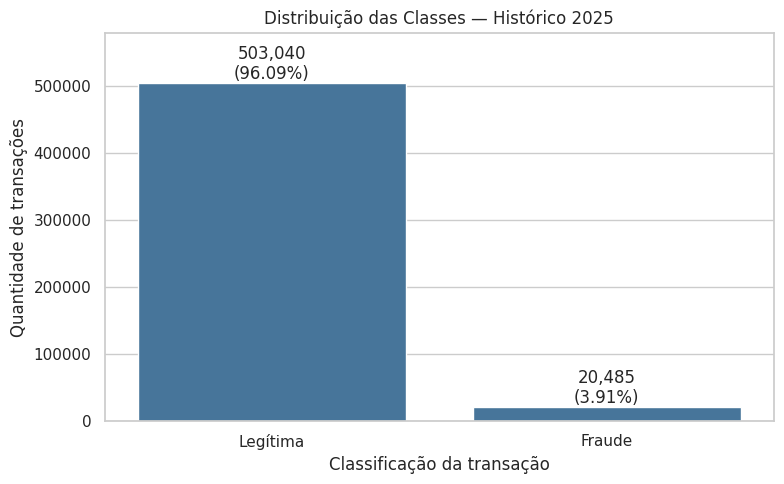

In [ ]:

# Distribuição de fraudes
distribuicao = (
    df["flag_fraude"]
    .value_counts()
    .rename(index={False: "Legítima", True: "Fraude"})
)

percentuais = distribuicao / len(df) * 100

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    x=distribuicao.index,
    y=distribuicao.values,
    ax=ax,
    color="#3977A8"
)

for i, (quantidade, percentual) in enumerate(
    zip(distribuicao.values, percentuais.values)
):
    ax.text(
        i, quantidade,
        f"{quantidade:,}\n({percentual:.2f}%)",
        ha="center",
        va="bottom"
    )

ax.set_title("Distribuição das Classes — Histórico 2025")
ax.set_xlabel("Classificação da transação")
ax.set_ylabel("Quantidade de transações")
ax.set_ylim(0, distribuicao.max() * 1.15)

plt.tight_layout()
plt.show()


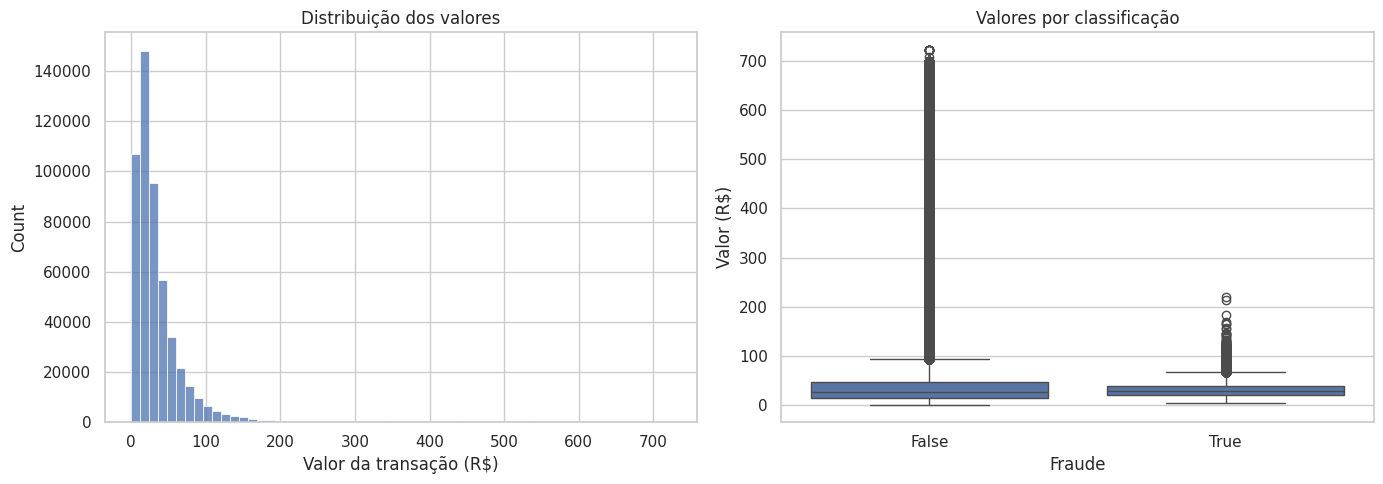

,count,mean,std,min,50%,90%,95%,99%,max
flag_fraude,,,,,,,,,
False,503040.0,44.496455,75.786833,0.50,25.11,80.411,120.780,499.6022,722.90
True,20485.0,30.861887,16.619127,4.41,27.21,51.490,62.376,88.9048,218.83


In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="valor_transacao",
    bins=60,
    ax=axes[0]
)

axes[0].set_title("Distribuição dos valores")
axes[0].set_xlabel("Valor da transação (R$)")

sns.boxplot(
    data=df,
    x="flag_fraude",
    y="valor_transacao",
    ax=axes[1]
)

axes[1].set_title("Valores por classificação")
axes[1].set_xlabel("Fraude")
axes[1].set_ylabel("Valor (R$)")

plt.tight_layout()
plt.show()

# Estatísticas por classe
display(
    df.groupby("flag_fraude")["valor_transacao"]
      .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
)


# **EDA - PARTE II**

,tipo_estabelecimento,transacoes,fraudes,taxa_fraude
2,Fuel,52163,3937,7.547495
1,Food & Beverage,104675,6939,6.629090
0,E-commerce,105223,3288,3.124792
4,Retail,104648,2623,2.506498
5,Supermarket,104225,2475,2.374670
3,Pharmacy,52591,1223,2.325493


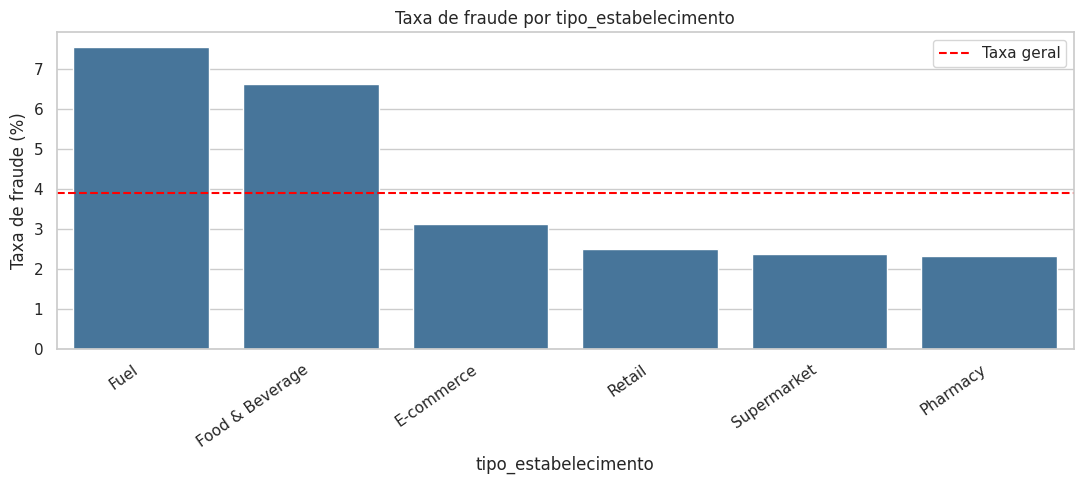

,device_type,transacoes,fraudes,taxa_fraude
1,mobile,291056,14306,4.915205
0,desktop,181262,5123,2.826296
2,tablet,51207,1056,2.062218


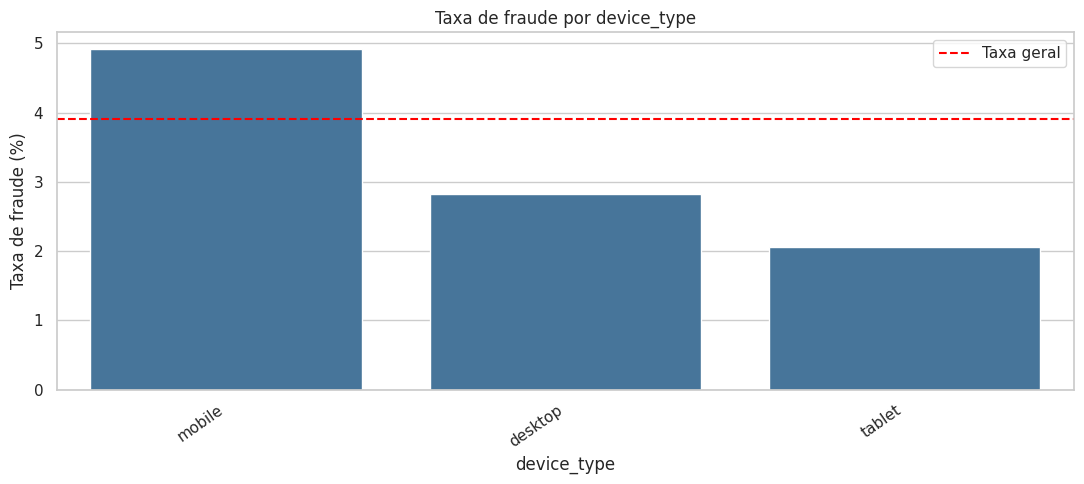

,is_new_device,transacoes,fraudes,taxa_fraude
1,True,86821,11199,12.898953
0,False,436704,9286,2.126383


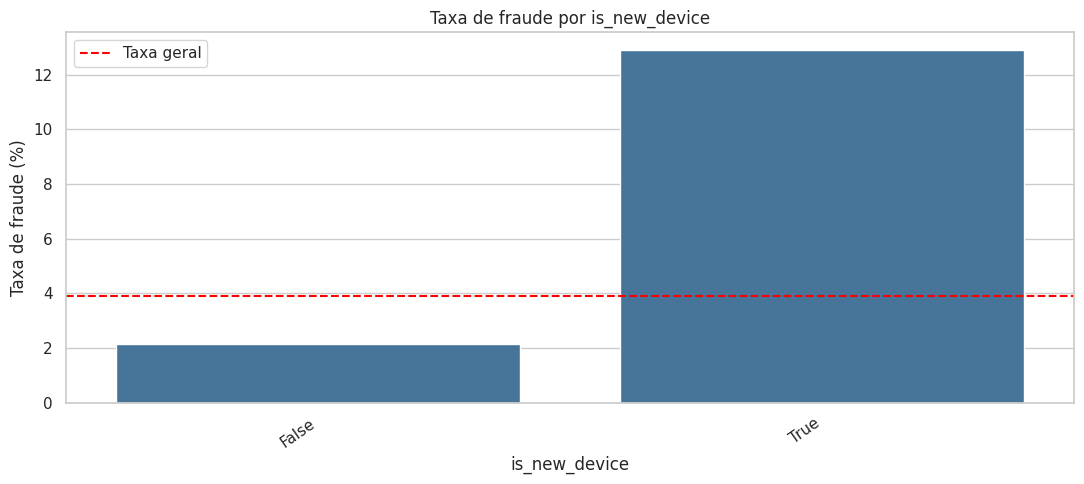

,turno,transacoes,fraudes,taxa_fraude
2,noite,130876,13403,10.240991
3,tarde,130871,4449,3.399531
0,madrugada,130850,1764,1.348109
1,manha,130928,869,0.663724


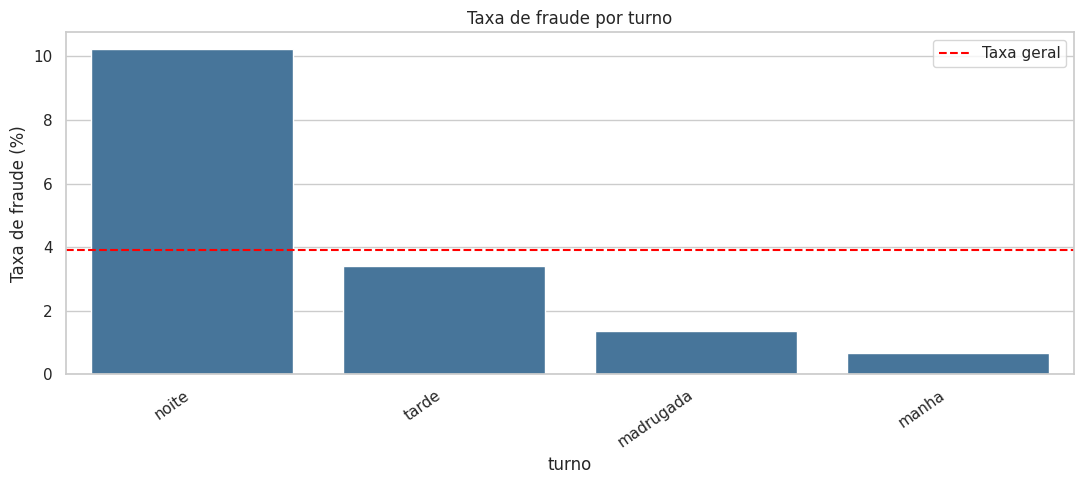

,valor_categoria,transacoes,fraudes,taxa_fraude
2,medio,185148,8563,4.624949
1,baixo,304015,11825,3.889611
0,alto,34362,97,0.282289


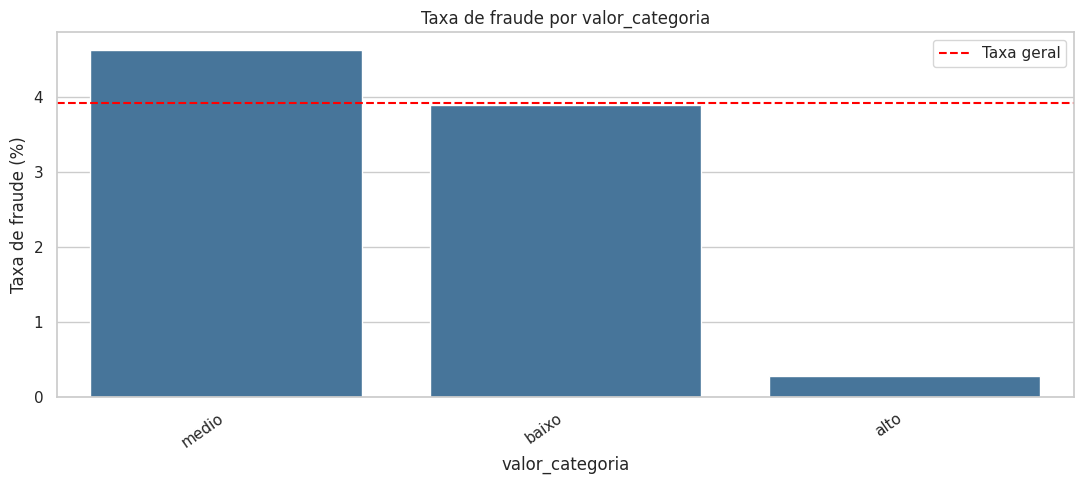

,cidade,transacoes,fraudes,taxa_fraude
6,São Paulo,74633,4095,5.486849
4,Rio de Janeiro,74963,4103,5.473367
0,Belo Horizonte,74528,2840,3.810648
2,Porto Alegre,74860,2794,3.732300
1,Curitiba,75116,2784,3.706268
3,Recife,74550,1943,2.606304
5,Salvador,74875,1926,2.572287


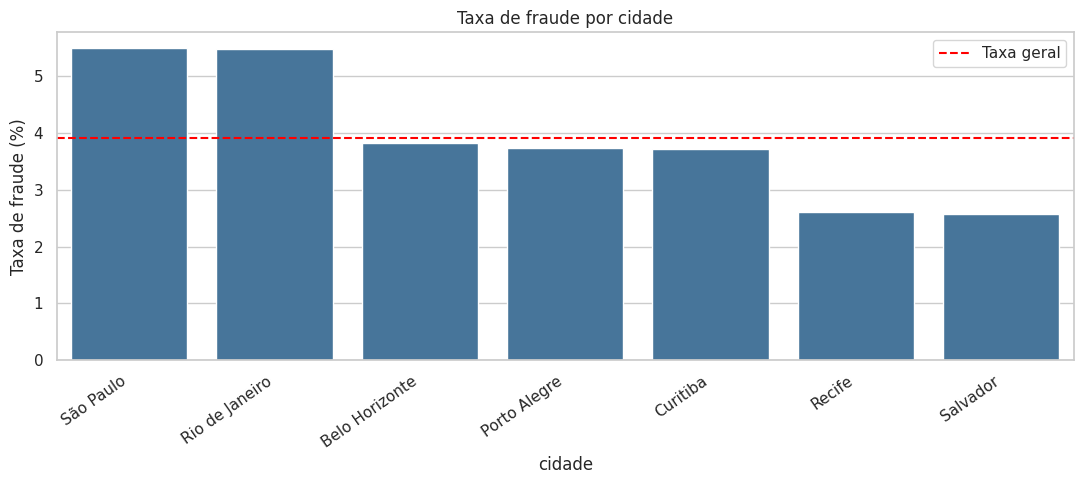

,cidade_regiao,transacoes,fraudes,taxa_fraude
1,Sudeste,224124,11038,4.924952
2,Sul,149976,5578,3.719262
0,Nordeste,149425,3869,2.589259


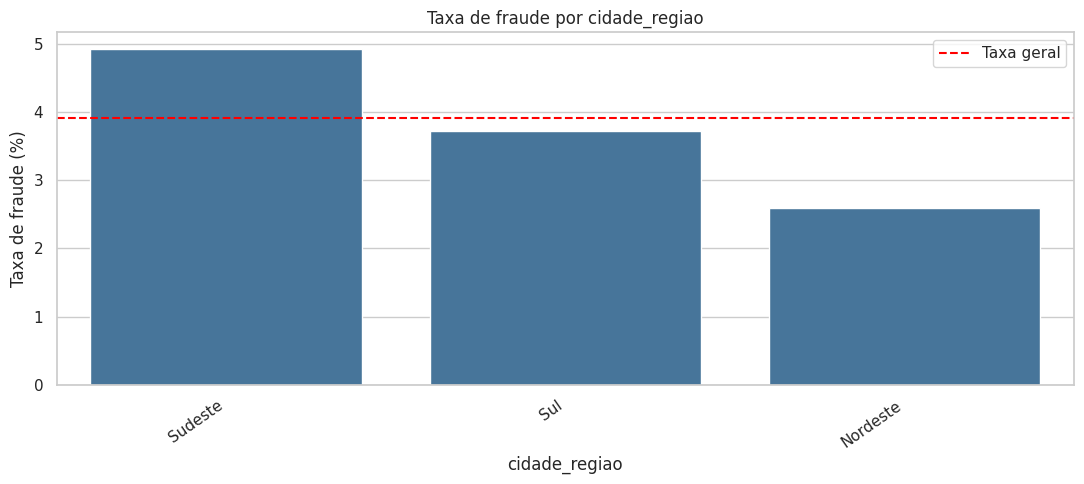

In [ ]:
# Considera o dataframe df carregado na etapa anterior
alvo = "flag_fraude"

def analisar_fraude_categoria(df, coluna):
    resumo = (
        df.groupby(coluna, dropna=False)[alvo]
        .agg(
            transacoes="count",
            fraudes="sum",
            taxa_fraude="mean"
        )
        .reset_index()
        .sort_values("taxa_fraude", ascending=False)
    )

    resumo["taxa_fraude"] *= 100

    display(resumo)

    plt.figure(figsize=(11, 5))

    ax = sns.barplot(
        data=resumo,
        x=coluna,
        y="taxa_fraude",
        color="#3977A8"
    )

    ax.axhline(
        df[alvo].mean() * 100,
        color="red",
        linestyle="--",
        label="Taxa geral"
    )

    ax.set_title(f"Taxa de fraude por {coluna}")
    ax.set_ylabel("Taxa de fraude (%)")
    ax.set_xlabel(coluna)
    plt.xticks(rotation=35, ha="right")
    plt.legend()
    plt.tight_layout()
    plt.show()

colunas = [
    "tipo_estabelecimento",
    "device_type",
    "is_new_device",
    "turno",
    "valor_categoria",
    "cidade",
    "cidade_regiao"
]

for coluna in colunas:
    analisar_fraude_categoria(df, coluna)


,transacoes,fraudes,taxa_fraude,valor_min,valor_max
decil_valor,,,,,
1,52370,212,0.404812,0.50,8.50
2,52378,1000,1.909199,8.51,12.36
3,52371,1921,3.668061,12.37,16.21
4,52319,2618,5.003918,16.22,20.37
5,52374,3277,6.256921,20.38,25.25
6,52357,3446,6.581737,25.26,31.27
7,52325,3358,6.417582,31.28,39.43
8,52330,2692,5.144277,39.44,52.08
9,52348,1602,3.060289,52.09,78.85


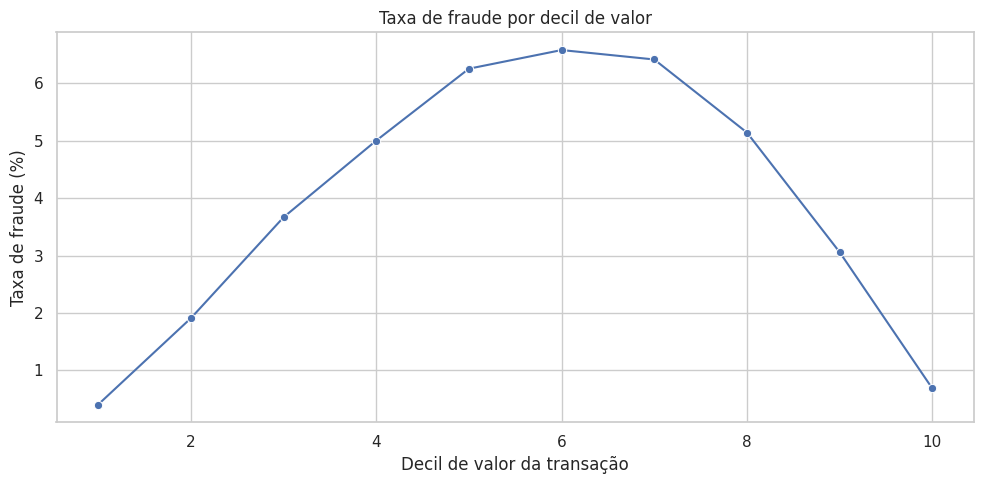

In [ ]:

# Criar decis de valor
df_eda = df.copy()

df_eda["decil_valor"] = pd.qcut(
    df_eda["valor_transacao"],
    q=10,
    labels=False,
    duplicates="drop"
) + 1

resumo_valor = (
    df_eda.groupby("decil_valor")
    .agg(
        transacoes=("flag_fraude", "size"),
        fraudes=("flag_fraude", "sum"),
        taxa_fraude=("flag_fraude", "mean"),
        valor_min=("valor_transacao", "min"),
        valor_max=("valor_transacao", "max")
    )
)

resumo_valor["taxa_fraude"] *= 100
display(resumo_valor)

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=resumo_valor,
    x="decil_valor",
    y="taxa_fraude",
    marker="o"
)
plt.title("Taxa de fraude por decil de valor")
plt.xlabel("Decil de valor da transação")
plt.ylabel("Taxa de fraude (%)")
plt.tight_layout()
plt.show()


is_new_device,False,True
turno,,
madrugada,0.68,4.92
manha,0.36,2.37
tarde,1.86,11.35
noite,5.77,29.17


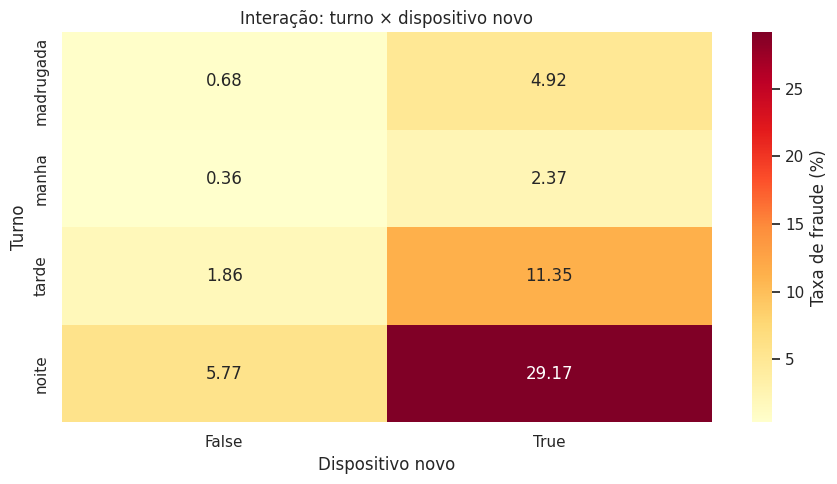

In [ ]:

# Taxa de fraude por turno e dispositivo novo
tabela = pd.pivot_table(
    df,
    values="flag_fraude",
    index="turno",
    columns="is_new_device",
    aggfunc="mean"
) * 100

ordem = ["madrugada", "manha", "tarde", "noite"]
tabela = tabela.reindex(ordem)

display(tabela.round(2))

plt.figure(figsize=(9, 5))

sns.heatmap(
    tabela,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    cbar_kws={"label": "Taxa de fraude (%)"}
)

plt.title("Interação: turno × dispositivo novo")
plt.xlabel("Dispositivo novo")
plt.ylabel("Turno")
plt.tight_layout()
plt.show()


# **EDA PARTE III**

,mes,transacoes,fraudes,taxa_fraude
0,2025-01,44463,1659,3.731192
1,2025-02,40162,1484,3.695035
2,2025-03,44473,1691,3.802307
3,2025-04,43028,1644,3.820768
4,2025-05,44464,1643,3.695124
5,2025-06,43022,1643,3.818976
6,2025-07,44464,1773,3.987496
7,2025-08,44448,1651,3.714453
8,2025-09,43042,1613,3.747502
9,2025-10,44468,1693,3.807232


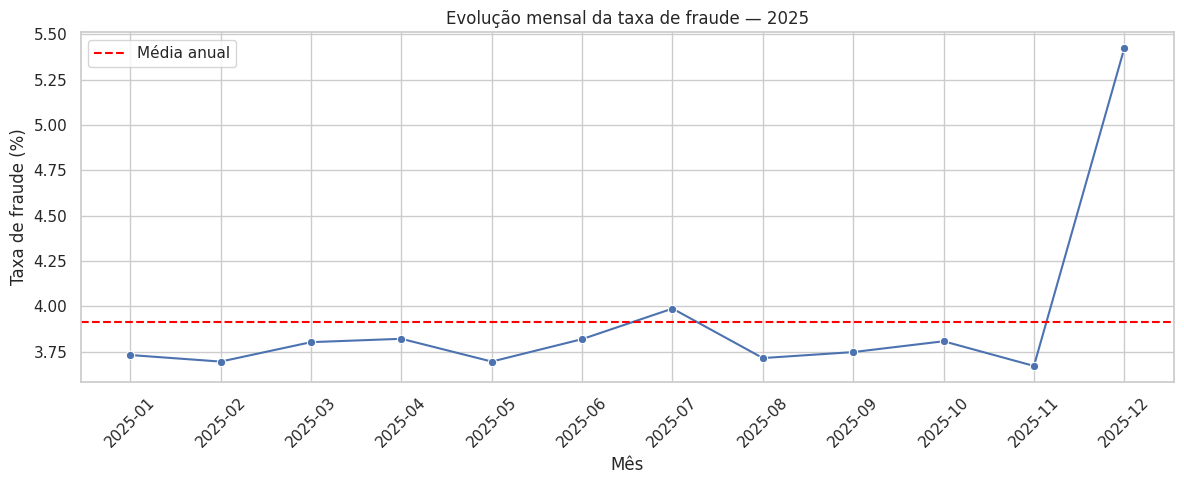

In [ ]:

# ETAPA 3.1 — Evolução temporal das fraudes

df_eda = df.copy()

df_eda["datahora_transacao"] = pd.to_datetime(
    df_eda["datahora_transacao"]
)

df_eda["mes"] = (
    df_eda["datahora_transacao"]
    .dt.to_period("M")
    .astype(str)
)

mensal = (
    df_eda.groupby("mes")["flag_fraude"]
    .agg(
        transacoes="size",
        fraudes="sum",
        taxa_fraude="mean"
    )
    .reset_index()
)

mensal["taxa_fraude"] *= 100

display(mensal)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=mensal,
    x="mes",
    y="taxa_fraude",
    marker="o"
)

plt.axhline(
    df_eda["flag_fraude"].mean() * 100,
    color="red",
    linestyle="--",
    label="Média anual"
)

plt.title("Evolução mensal da taxa de fraude — 2025")
plt.xlabel("Mês")
plt.ylabel("Taxa de fraude (%)")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()


,tipo_estabelecimento,periodo,transacoes,fraudes,taxa_fraude
0,E-commerce,Dezembro,9140,930,10.175055
1,E-commerce,Janeiro-Novembro,96083,2358,2.454128
2,Food & Beverage,Dezembro,8951,576,6.435035
3,Food & Beverage,Janeiro-Novembro,95724,6363,6.647236
4,Fuel,Dezembro,4365,358,8.201604
5,Fuel,Janeiro-Novembro,47798,3579,7.487761
6,Pharmacy,Dezembro,4407,88,1.996823
7,Pharmacy,Janeiro-Novembro,48184,1135,2.355554
8,Retail,Dezembro,8824,241,2.731188
9,Retail,Janeiro-Novembro,95824,2382,2.485807


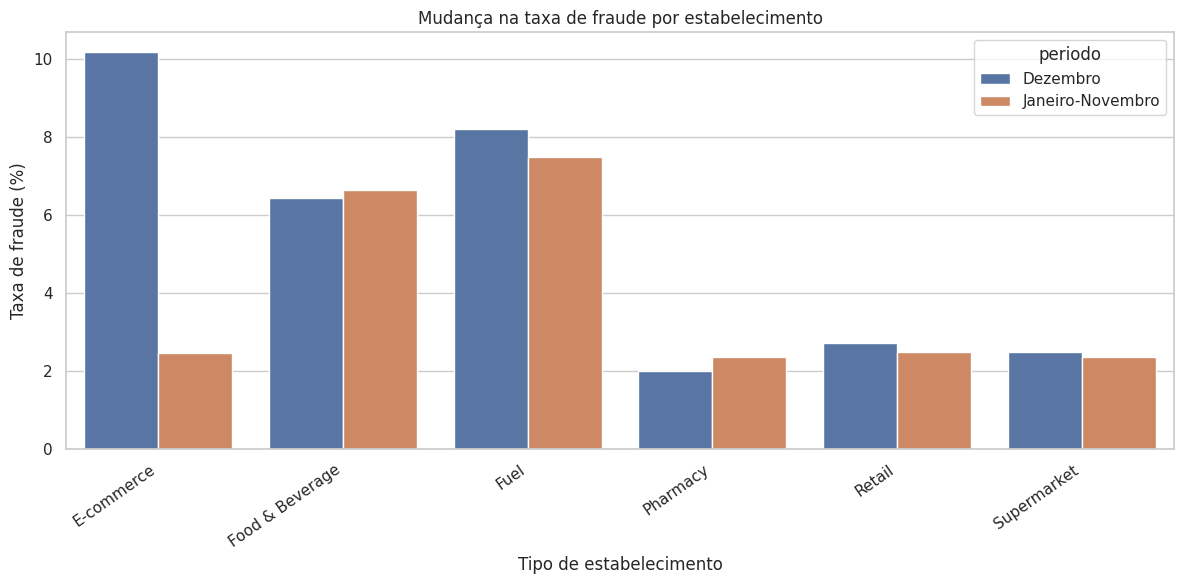

In [ ]:

# ETAPA 3.3 — Identificar mudanças em dezembro

df_eda["periodo"] = np.where(
    df_eda["mes"] == "2025-12",
    "Dezembro",
    "Janeiro-Novembro"
)

comparacao = (
    df_eda.groupby(
        ["tipo_estabelecimento", "periodo"]
    )["flag_fraude"]
    .agg(
        transacoes="size",
        fraudes="sum",
        taxa_fraude="mean"
    )
    .reset_index()
)

comparacao["taxa_fraude"] *= 100

display(comparacao)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparacao,
    x="tipo_estabelecimento",
    y="taxa_fraude",
    hue="periodo"
)

plt.title("Mudança na taxa de fraude por estabelecimento")
plt.xlabel("Tipo de estabelecimento")
plt.ylabel("Taxa de fraude (%)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [ ]:

# ETAPA 3.4 — Data drift numérico

from scipy.stats import ks_2samp

variaveis_numericas = [
    "valor_transacao",
    "score_interno",
    "temperatura_celsius"
]

resultados = []

for coluna in variaveis_numericas:
    historico = df[coluna].dropna()
    janeiro = df_jan[coluna].dropna()

    teste = ks_2samp(historico, janeiro)

    resultados.append({
        "variavel": coluna,
        "media_2025": historico.mean(),
        "media_janeiro": janeiro.mean(),
        "ks_statistic": teste.statistic,
        "p_value": teste.pvalue
    })

drift_numerico = pd.DataFrame(resultados)

display(drift_numerico.round(5))


,variavel,media_2025,media_janeiro,ks_statistic,p_value
0,valor_transacao,43.96295,44.12986,0.00349,0.69921
1,score_interno,500.37354,499.48741,0.00383,0.58264
2,temperatura_celsius,24.00520,23.97885,0.00397,0.53674
